In [1]:
# 1. Configuration
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

INPUT_PATH = ROOT / "data/paper-example-uncertain-activity.jsonocel"
UNCERTAINTY_ENABLED = True
UNCERTAINTY_KINDS = ("activity",)  # only supported uncertainty dimension
PROPERTY_MODE = "global"        # "per_world" (exact) or "global" (recorded-label properties)
ACTIVITY_COVERAGE = 1.0
MAX_WORLDS = None                   # None evaluates every world, up to 10,000
SEED = 42                           # reproducible selection when MAX_WORLDS limits worlds
SAVE_PNG = True
RUN_COMPARISON = True
OUTPUT_DIR = ROOT / "output"


In [2]:
# 2. Load and validate the annotated OCEL 2.0 log
from src.uncertainty.parsing import load_annotated_ocel
from src.uncertainty.analysis import log_metrics, interval_table, compare_modes
from src.uncertainty.pipeline import run_uncertain_df2
from IPython.display import display, Image
import pandas as pd

log = load_annotated_ocel(INPUT_PATH)
print(f"Loaded {INPUT_PATH.name}")


Loaded paper-example-uncertain-activity.jsonocel


In [3]:
# 3. Data and uncertainty overview
metrics = log_metrics(log)
display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))
display(pd.DataFrame([
    {"event_id": event_id, "recorded": log.recorded[event_id], "candidates": ", ".join(candidates), "candidate_count": len(candidates)}
    for event_id, candidates in sorted(log.uncertain_choices.items())
]))
print("Possible worlds with current uncertainty setting:",
      log.possible_worlds if UNCERTAINTY_ENABLED else 1)


,value
events,8
objects,8
event_object_relations,24
uncertain_activity_events,2
activity_candidates,4
possible_worlds,4
uncertainty_types,[activity]


,event_id,recorded,candidates,candidate_count
0,e4,REORDER,"REORDER, REQUEST",2
1,e7,SENDOUT,"CHARGE, SENDOUT",2


Possible worlds with current uncertainty setting: 4


In [4]:
# 4. Run the configured pipeline
result = run_uncertain_df2(
    INPUT_PATH,
    uncertainty_enabled=UNCERTAINTY_ENABLED,
    uncertainty_kinds=UNCERTAINTY_KINDS,
    property_mode=PROPERTY_MODE,
    activity_coverage=ACTIVITY_COVERAGE,
    max_worlds=MAX_WORLDS,
    seed=SEED,
    save_png=SAVE_PNG,
    output_dir=OUTPUT_DIR,
)
print(f"Worlds evaluated: {result.evaluated_worlds}/{result.total_worlds}")
print(f"Property mode: {result.property_mode}; exhaustive: {result.exhaustive}; exact: {result.exact}")
print(f"Elapsed: {result.elapsed_seconds:.3f} s")
print("Selected world indices:", result.selected_world_indices)


Worlds evaluated: 4/4
Property mode: global; exhaustive: True; exact: False
Elapsed: 0.068 s
Selected world indices: [0, 1, 2, 3]


/Users/ceren/Documents/GitHub/DF2-Miner/output/df2_20261108_123039_616828.png


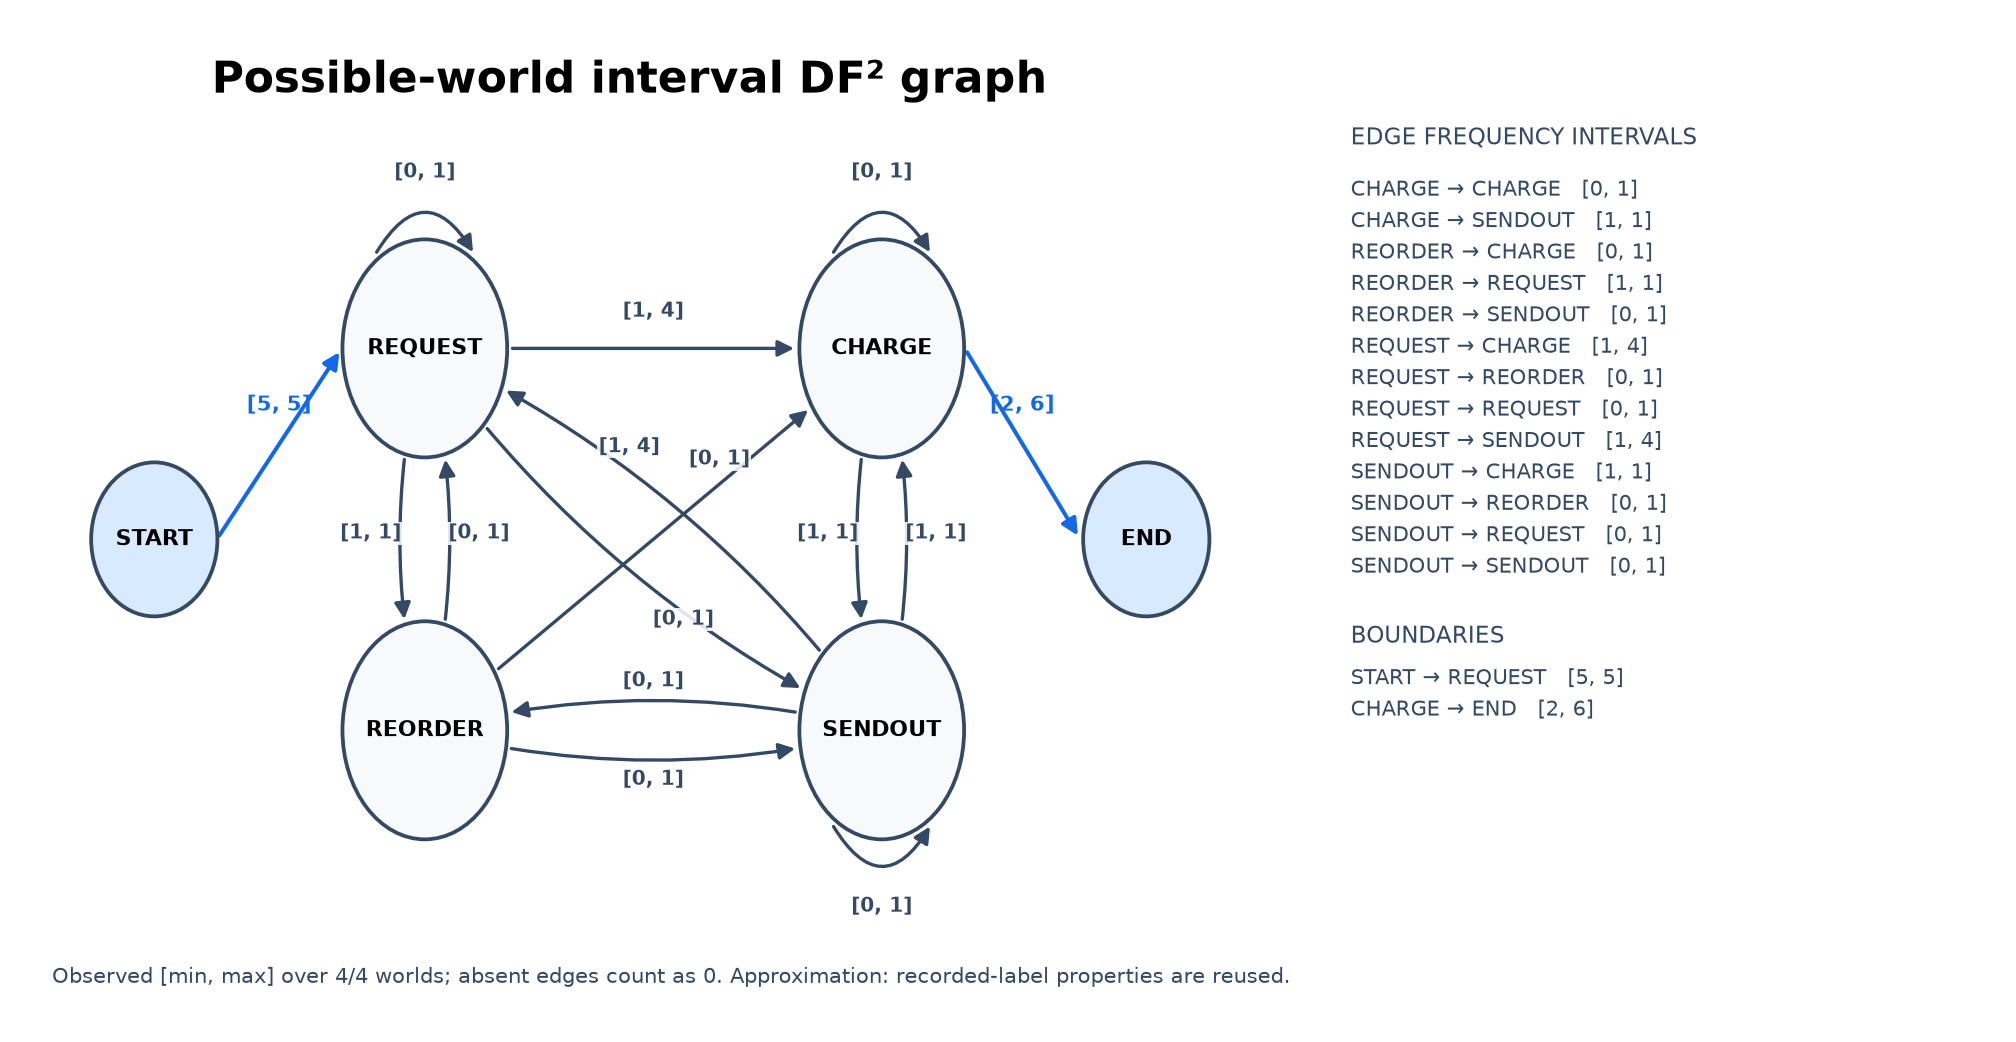

In [5]:
# 5. View the saved graph
if result.png_path:
    print(result.png_path)
    display(Image(filename=str(result.png_path)))
else:
    print("PNG output disabled")


In [6]:
# 6. Edge, start, and end intervals
print("Edges")
display(interval_table(result.intervals, "edges"))
print("Start activities")
display(interval_table(result.intervals, "starts"))
print("End activities")
display(interval_table(result.intervals, "ends"))


Edges


,source,target,min,max,width
0,CHARGE,CHARGE,0,1,1
1,CHARGE,SENDOUT,1,1,0
2,REORDER,CHARGE,0,1,1
3,REORDER,REQUEST,1,1,0
4,REORDER,SENDOUT,0,1,1
5,REQUEST,CHARGE,1,4,3
6,REQUEST,REORDER,0,1,1
7,REQUEST,REQUEST,0,1,1
8,REQUEST,SENDOUT,1,4,3
9,SENDOUT,CHARGE,1,1,0


Start activities


,activity,min,max,width
0,REQUEST,5,5,0


End activities


,activity,min,max,width
0,CHARGE,2,6,4


In [7]:
# 7. Graph metrics
summary = result.intervals.metrics()
summary.update({"total_worlds": result.total_worlds,
                "evaluated_worlds": result.evaluated_worlds,
                "elapsed_seconds": result.elapsed_seconds,
                "exact": result.exact})
display(pd.DataFrame([summary]).T.rename(columns={0: "value"}))


,value
edges,13
always_present_edges,5
possible_only_edges,8
variable_edges,10
total_edge_interval_width,14
widest_edge_interval,3
start_activities,1
end_activities,1
total_worlds,4
evaluated_worlds,4


In [8]:
# 8. Optional property-mode comparison on the same selected worlds
if RUN_COMPARISON:
    other_mode = "global" if PROPERTY_MODE == "per_world" else "per_world"
    other = run_uncertain_df2(
        INPUT_PATH, uncertainty_enabled=UNCERTAINTY_ENABLED,
        uncertainty_kinds=UNCERTAINTY_KINDS, property_mode=other_mode,
        activity_coverage=ACTIVITY_COVERAGE, max_worlds=MAX_WORLDS,
        seed=SEED, save_png=False,
    )
    per_world, global_result = (result, other) if PROPERTY_MODE == "per_world" else (other, result)
    comparison = compare_modes(per_world, global_result)
    display(pd.DataFrame([{
        "changed_edges": comparison["changed_edges"],
        "per_world_seconds": comparison["per_world_seconds"],
        "global_seconds": comparison["global_seconds"],
        "worlds_evaluated": result.evaluated_worlds,
    }]))
    display(pd.DataFrame([
        {"source": a, "target": b, "per_world": exact, "global": approx}
        for (a, b), (exact, approx) in sorted(comparison["changed_edge_bounds"].items())
    ]))


,changed_edges,per_world_seconds,global_seconds,worlds_evaluated
0,2,0.088633,0.067887,4


,source,target,per_world,global
0,CHARGE,SENDOUT,"(1, 2)","(1, 1)"
1,SENDOUT,REQUEST,"(0, 2)","(0, 1)"
